# Data preprocessing: fingerprint0.txt to autoencoder input

This notebook walks through the bootstrap file one representation at a time. Raw-file parsing uses GUFU's shared prepare_dataset_files API, so the notebook does not introduce a second parser with different BSSID, filtering, or missing-value rules. Later cells expose the prepared vocabulary, RSSI matrix, observation mask, named AE normalization, and final tensor.

Run from the repository root. This notebook prepares and inspects data only; it does not train a model or write artifacts.

## Step 1 — Select the source and preprocessing policy

The source uses the GUFU database text format: each line starts with x,y, followed by space-separated AP records. The bootstrap settings below match gufu.py: keep all finite readings, keep empty scans, drop malformed rows, and retain the strongest duplicate reading for an AP within one scan.

In [2]:
from unknot_data.base import GeoLocationData
from unknot_data.vector import WifiBssidVector, WifiRssiVector
from unknot_data.wifi_networks import WifiNetwork
from unknot_data.rssi_index import RssiIndex, RssiIntegerIndex
from unknot_data.data_viz import AxisGrid
from unknot_data.utils import load_scan_from_txt

In [2]:
bssids, poses = load_scan_from_txt(
    source_path="input/GF/fingerprint0.txt",
    geo_reference = GeoLocationData(longitude=-74.6520576, latitude=40.3637847, altitude=0.0)
)

wifi_network = WifiNetwork(
    bssids=sorted({b for bssid in bssids[:-100] for b in bssid.bssid})
)

In [ ]:
bssids_val, poses_val = load_scan_from_txt(
    source_path="input/GF/fingerprint1.txt",
    geo_reference = GeoLocationData(longitude=-74.6520576, latitude=40.3637847, altitude=0.0)
)
rssis_val = wifi_network.bssid2rssi(bssids_val)

In [ ]:
bssids0 =sorted({b for bssid in bssids for b in bssid.bssid})
bssids1 =sorted({b for bssid in bssids_val for b in bssid.bssid})

In [19]:
print(len(bssids0), len(bssids1))

print(
    len([x for x in bssids0 if x not in bssids1]),
    len([x for x in bssids1 if x not in bssids0])
)

1022 999
188 165


In [3]:
import numpy as np

bssids_train = bssids[:-100]
poses_train = poses[:-100]
rssis_train = wifi_network.bssid2rssi(bssids_train)

rssi_index = RssiIndex(
    positions=np.stack([pose.arr() for pose in poses_train]),
    rssis = np.stack([rssi.arr() for rssi in rssis_train]),
    dim=len(wifi_network.bssids)
)

In [4]:
bssids_test = bssids[-100:]
poses_test = poses[-100:]
rssis_test = wifi_network.bssid2rssi(bssids_test)

In [9]:
preds = np.stack([rssi_index.predict(rssi.arr(), k=10) for rssi in rssis_test])
targs = np.stack([pose.arr() for pose in poses_test])

error_test = np.linalg.norm(preds-targs, axis=-1).mean()
print(error_test)

35.37371846167573


In [16]:
preds = np.stack([rssi_index.predict(rssi.arr(), k=10) for rssi in rssis_val])
targs = np.stack([pose.arr() for pose in poses_val])

error_val = np.linalg.norm(preds-targs, axis=-1).mean()
print(error_val)

20.02935732337639


In [101]:
import glob

dataset_paths = sorted(glob.glob("input/1F/finger*"))

datas = []
bssids_completes = []

for dataset_path in dataset_paths:
    bssids, poses = load_scan_from_txt(
        source_path=dataset_path,
        geo_reference = GeoLocationData(longitude=-74.6520576, latitude=40.3637847, altitude=0.0)
    )
    datas.append({'bssids': bssids, 'poses': poses})
    bssids_completes.append(sorted({b for bssid in bssids for b in bssid.bssid}))
    
print(f"(n_bssids, n_poses)={[(len(data['bssids']), len(data['poses'])) for data in datas]}")
print(f"n_vocabularies={[len(x) for x in bssids_completes]}")

(n_bssids, n_poses)=[(258, 258), (258, 258), (419, 419), (419, 419), (1448, 1448)]
n_vocabularies=[317, 317, 280, 347, 517]


In [102]:
import numpy as np

overlap_matrix = np.zeros((5, 5))

for i in range(len(bssids_completes)):
    for j in range(len(bssids_completes)):
        i_not_j = len([x for x in bssids_completes[i] if x not in bssids_completes[j]])
        overlap_matrix[i, j] = i_not_j
        
overlap_matrix
        

array([[  0.,   0.,  60.,  60.,  44.],
       [  0.,   0.,  60.,  60.,  44.],
       [ 23.,  23.,   0.,   0.,   0.],
       [ 90.,  90.,  67.,   0.,   0.],
       [244., 244., 237., 170.,   0.]])

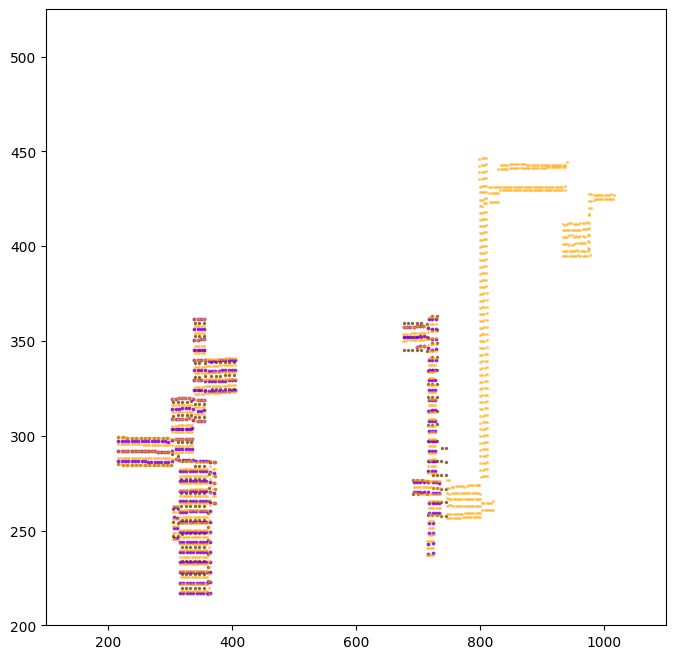

In [103]:
Ax = AxisGrid(1, 1, (8, 8))

markers = ['o', 'x', 's', 'D', '*']
colors = ['r', 'g', 'b', 'm', 'orange']

for i, (data, marker, color) in enumerate(zip(datas, markers, colors)):
    Ax.scatter_xy(0, data['poses'], c=color, marker=marker, alpha=0.5, s=2)
    Ax[0].set_xlim(100, 1100)
    Ax[0].set_ylim(200, 525)

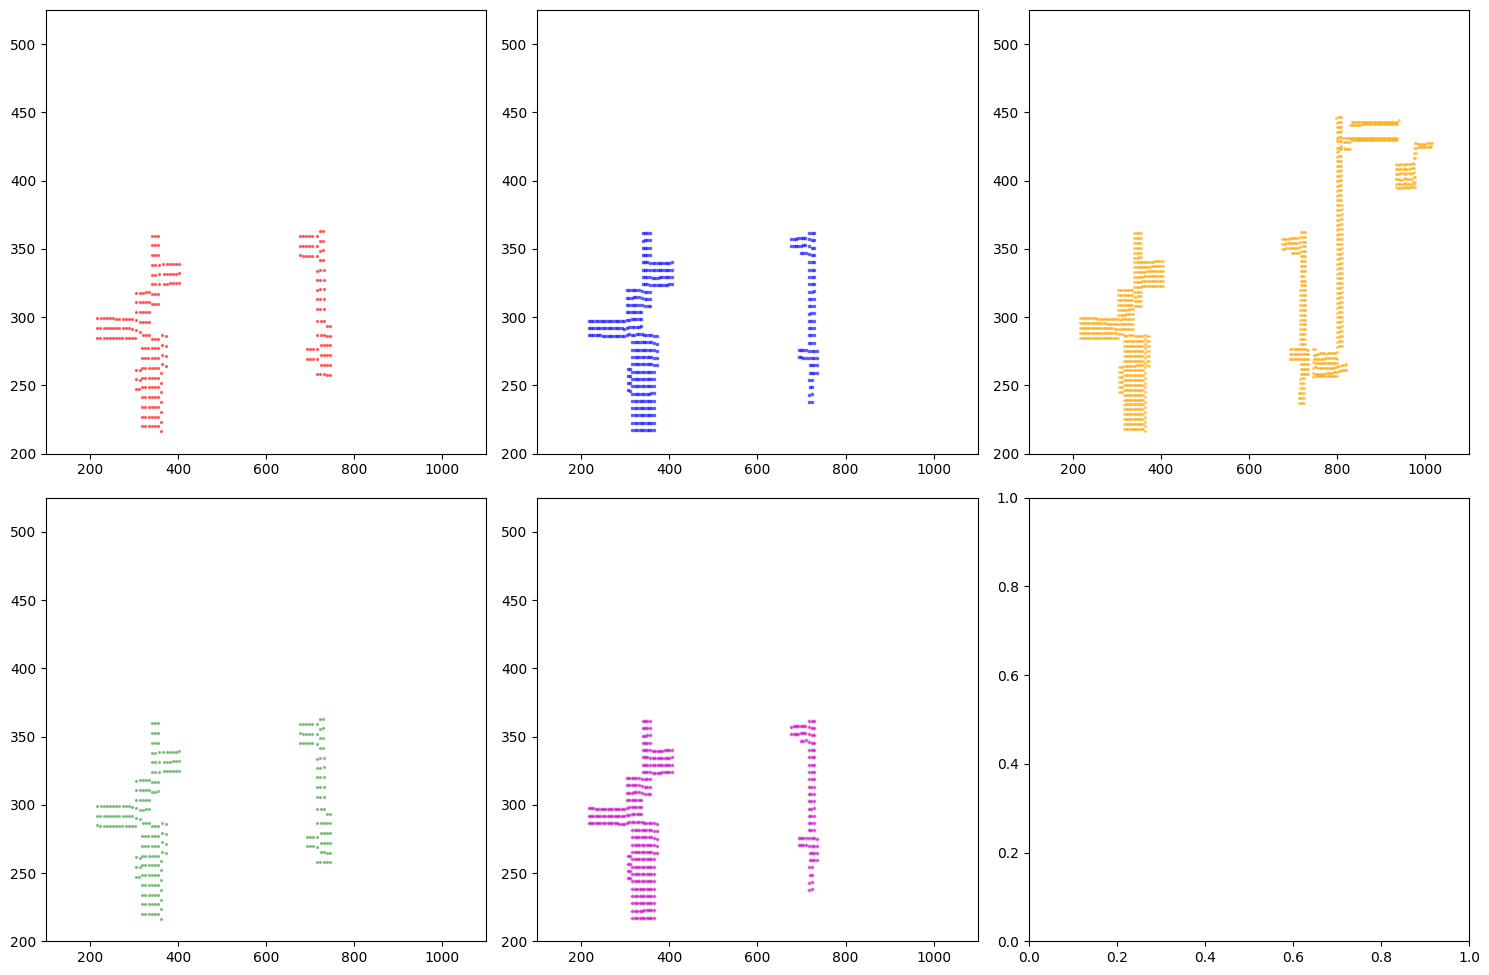

In [105]:
import matplotlib.pyplot as plt

Ax = AxisGrid(5, 3, (5, 5))

for i, (data, marker, color) in enumerate(zip(datas, markers, colors)):
    Ax.scatter_xy(i, data['poses'], c=color, marker=marker, alpha=0.5, s=2)
    Ax[i].set_xlim(100, 1100)
    Ax[i].set_ylim(200, 525)
    
plt.tight_layout()